# AI Layoff Risk Predictor: Logistic Regression
**AI101 Mini-Project | Team 28** 

**Problem statement.** Predict whether an employee's layoff risk is **Low, Medium or High** from job, personal and AI-use features.

**Motivation.** As AI tools spread through workplaces, it helps to know which job traits go with higher layoff risk, for example routine tasks versus creative work.

**Task.** Multi-class classification with **Logistic Regression** (scikit-learn).

**Dataset.** Kaggle, **AI Impact on Jobs and Layoff Risk Dataset** . It is synthetic: 20,000 rows, 16 columns (9 numeric features, 6 categorical features and the label Layoff Risk)

In [6]:
%matplotlib inline
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc, classification_report,
                             f1_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

RANDOM_STATE = 42
DATA_PATH =  "ai-impact-jobs-layoff-risk-dataset.csv"  
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
TARGET = "Layoff_Risk"
LABELS = ["Low", "Medium", "High"]
COLORS = {"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#c0392b"}
pd.set_option("display.width", 200)

## 1. Load the data

In [7]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 20,000 | Columns: 16


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14  AI_Training_Hours

## 2. Data understanding with statistics

In [9]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)


stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T.round(2)
stats

Numeric features: ['Age', 'Years_of_Experience', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours']
Categorical features: ['Education_Level', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'AI_Adoption_Level']


,mean,median,std,min,max
Age,40.36,40.0,11.53,21.0,60.0
Years_of_Experience,7.27,7.0,4.72,0.0,32.0
Routine_Task_Percentage,51.89,52.0,24.44,10.0,94.0
Creativity_Requirement,47.79,48.0,26.10,0.0,100.0
Human_Interaction_Level,60.06,62.0,22.27,20.0,99.0
Number_of_AI_Tools_Used,2.46,2.0,2.10,0.0,10.0
AI_Usage_Hours_Per_Week,6.77,5.0,6.09,0.0,30.0
Tasks_Automated_Percentage,37.23,35.0,20.00,4.0,93.0
AI_Training_Hours,12.62,8.0,13.55,0.0,79.0


Layoff_Risk
Low       6602
Medium    6601
High      6797
Name: count, dtype: int64


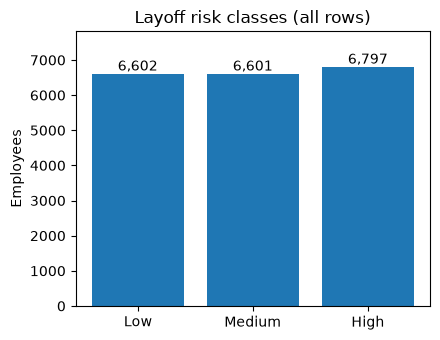

In [10]:
counts = df[TARGET].value_counts().reindex(LABELS)
print(counts)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(counts.index, counts.values)
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f"{v:,}", ha="center")
ax.set(title="Layoff risk classes (all rows)", ylabel="Employees", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUT_DIR / "class_balance.png", dpi=150)
plt.show()